In [3]:

print("CSET485 Assignment 1")
print("Setup started successfully!")

import pandas as pd
import numpy as np
import sklearn

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Roll number random_state:", 736)


CSET485 Assignment 1
Setup started successfully!
Pandas version: 2.2.3
NumPy version: 2.1.3
Scikit-learn version: 1.6.1
Roll number random_state: 736


In [4]:


import pandas as pd


url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

columns = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week",
    "native_country", "income"
]

df = pd.read_csv(
    url,
    names=columns,
    skipinitialspace=True,
    na_values="?"
)


print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())


Dataset loaded successfully!
Rows and columns: (32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [5]:


print("Income distribution:")
print(df["income"].value_counts())


print("\nMissing values in each column:")
print(df.isnull().sum())


print("\nDataset information:")
df.info()


Income distribution:
income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Missing values in each column:
age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      30718 non-null  object

In [6]:

df["income_binary"] = df["income"].map({
    "<=50K": 0,
    ">50K": 1
})

print(df["income_binary"].value_counts())
print("Missing values in target:", df["income_binary"].isnull().sum())
print("Dataset shape:", df.shape)


income_binary
0    24720
1     7841
Name: count, dtype: int64
Missing values in target: 0
Dataset shape: (32561, 16)


In [7]:

from sklearn.model_selection import train_test_split

X = df.drop(columns=["income", "income_binary"])
y = df["income_binary"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=736,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training data: (22792, 14)
Testing data: (9769, 14)
Training target: (22792,)
Testing target: (9769,)


In [8]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [9]:

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)


Processed training data: (22792, 105)
Processed testing data: (9769, 105)


In [10]:

linear_model = LinearRegression()
linear_model.fit(X_train_processed, y_train)

logistic_model = LogisticRegression(max_iter=1000, random_state=736)
logistic_model.fit(X_train_processed, y_train)

linear_predictions = linear_model.predict(X_test_processed)
linear_threshold = np.median(linear_predictions)
linear_classes = (linear_predictions >= linear_threshold).astype(int)

logistic_probabilities = logistic_model.predict_proba(X_test_processed)[:, 1]
logistic_classes = (logistic_probabilities >= 0.5).astype(int)

print("Linear Regression trained successfully")
print("Logistic Regression trained successfully")
print("Linear Regression threshold:", linear_threshold)
print("Logistic Regression threshold: 0.5")


Linear Regression trained successfully
Logistic Regression trained successfully
Linear Regression threshold: 0.2260530196729294
Logistic Regression threshold: 0.5


# New Section

In [11]:
print("Linear Regression accuracy:", accuracy_score(y_test, linear_classes))
print("Logistic Regression accuracy:", accuracy_score(y_test, logistic_classes))

print("\nAgreement Matrix (Rows = Linear, Columns = Logistic):")
print(confusion_matrix(linear_classes, logistic_classes))

mismatch_count = np.sum(linear_classes != logistic_classes)

print("\nMismatch count:", mismatch_count)
print("Mismatch percentage:", round(mismatch_count / len(y_test) * 100, 2), "%")

print("\nLogistic Regression Classification Report:")
print(classification_report(y_test, logistic_classes))

Linear Regression accuracy: 0.7100010236462279
Logistic Regression accuracy: 0.8529020370559934

Agreement Matrix (Rows = Linear, Columns = Logistic):
[[4872   12]
 [3022 1863]]

Mismatch count: 3034
Mismatch percentage: 31.06 %

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.94      0.91      7417
           1       0.74      0.59      0.66      2352

    accuracy                           0.85      9769
   macro avg       0.81      0.76      0.78      9769
weighted avg       0.85      0.85      0.85      9769



In [12]:
!pip -q install statsmodels

In [13]:
import statsmodels.api as sm
import pandas as pd
import numpy as np

predictors = [
    "age",
    "education_num",
    "hours_per_week",
    "capital_gain"
]

def fit_group(group_name):
    mask = X_train["sex"].eq(group_name)

    data = X_train.loc[mask, predictors].copy()
    target = y_train.loc[mask]

    data = data.fillna(data.median())
    data = sm.add_constant(data)

    model = sm.Logit(target, data).fit(disp=False, maxiter=200)

    ci = model.conf_int()

    results = pd.DataFrame({
        "Coefficient": model.params,
        "CI Lower": ci[0],
        "CI Upper": ci[1],
        "P-value": model.pvalues
    })

    return model, results

female_model, female_results = fit_group("Female")
male_model, male_results = fit_group("Male")

print("FEMALE SUBGROUP")
display(female_results)

print("MALE SUBGROUP")
display(male_results)

FEMALE SUBGROUP


,Coefficient,CI Lower,CI Upper,P-value
const,-8.032557,-8.593741,-7.471374,3.555645e-173
age,0.029405,0.023350,0.035461,1.770919e-21
education_num,0.361230,0.322785,0.399674,9.775918e-76
hours_per_week,0.017987,0.011045,0.024929,3.805154e-07
capital_gain,0.000322,0.000278,0.000367,3.079428e-46


MALE SUBGROUP


,Coefficient,CI Lower,CI Upper,P-value
const,-8.181061,-8.494023,-7.868099,0.000000e+00
age,0.046912,0.043575,0.050249,3.641702e-167
education_num,0.341411,0.323549,0.359273,3.714662e-307
hours_per_week,0.037942,0.034407,0.041478,3.178337e-98
capital_gain,0.000284,0.000258,0.000309,3.680574e-104


In [14]:
comparison = pd.DataFrame({
    "Female coefficient": female_model.params,
    "Male coefficient": male_model.params
})

comparison["Difference (Female - Male)"] = (
    comparison["Female coefficient"] - comparison["Male coefficient"]
)

display(comparison)

,Female coefficient,Male coefficient,Difference (Female - Male)
const,-8.032557,-8.181061,0.148504
age,0.029405,0.046912,-0.017507
education_num,0.361230,0.341411,0.019819
hours_per_week,0.017987,0.037942,-0.019955
capital_gain,0.000322,0.000284,0.000039


In [15]:
full_data = X_train[predictors].copy()
full_data = full_data.fillna(full_data.median())
full_data = sm.add_constant(full_data)

full_model = sm.Logit(y_train, full_data).fit(disp=False, maxiter=200)

full_ci = full_model.conf_int()

full_results = pd.DataFrame({
    "Coefficient": full_model.params,
    "CI Lower": full_ci[0],
    "CI Upper": full_ci[1],
    "P-value": full_model.pvalues
})

print("FULL-SAMPLE RESULTS")
display(full_results)

print("FULL vs FEMALE vs MALE")
display(pd.DataFrame({
    "Full": full_model.params,
    "Female": female_model.params,
    "Male": male_model.params
}))

FULL-SAMPLE RESULTS


,Coefficient,CI Lower,CI Upper,P-value
const,-8.368219,-8.636260,-8.100178,0.000000e+00
age,0.043992,0.041148,0.046835,5.191955e-202
education_num,0.333388,0.317569,0.349208,0.000000e+00
hours_per_week,0.040491,0.037435,0.043547,1.132139e-148
capital_gain,0.000298,0.000276,0.000320,1.560055e-153


FULL vs FEMALE vs MALE


,Full,Female,Male
const,-8.368219,-8.032557,-8.181061
age,0.043992,0.029405,0.046912
education_num,0.333388,0.361230,0.341411
hours_per_week,0.040491,0.017987,0.037942
capital_gain,0.000298,0.000322,0.000284


In [16]:
reduced_predictors = [
    "education_num",
    "hours_per_week",
    "capital_gain"
]

reduced_data = X_train[reduced_predictors].copy()
reduced_data = reduced_data.fillna(reduced_data.median())
reduced_data = sm.add_constant(reduced_data)

reduced_model = sm.Logit(y_train, reduced_data).fit(disp=False, maxiter=200)

common_predictors = ["education_num", "hours_per_week", "capital_gain"]

confounder_comparison = pd.DataFrame({
    "Full Model": full_model.params[common_predictors],
    "Reduced Model": reduced_model.params[common_predictors]
})

confounder_comparison["Percentage Change"] = (
    (confounder_comparison["Reduced Model"] - confounder_comparison["Full Model"])
    / confounder_comparison["Full Model"].abs()
) * 100

display(confounder_comparison)

,Full Model,Reduced Model,Percentage Change
education_num,0.333388,0.332094,-0.388123
hours_per_week,0.040491,0.038588,-4.700241
capital_gain,0.000298,0.000317,6.564613


In [17]:
high_confidence_wrong = (
    ((logistic_probabilities >= 0.75) & (y_test.to_numpy() == 0)) |
    ((logistic_probabilities <= 0.25) & (y_test.to_numpy() == 1))
)

wrong_indices = np.where(high_confidence_wrong)[0]

print("High-confidence wrong predictions:", len(wrong_indices))
print(
    "Percentage of test set:",
    round(len(wrong_indices) / len(y_test) * 100, 2),
    "%"
)

High-confidence wrong predictions: 454
Percentage of test set: 4.65 %


In [18]:
wrong_positions = np.where(high_confidence_wrong)[0]

wrong_sample_positions = np.random.RandomState(736).choice(
    wrong_positions,
    size=min(50, len(wrong_positions)),
    replace=False
)

wrong_sample = X_test.iloc[wrong_sample_positions].copy()
wrong_sample["Actual"] = y_test.iloc[wrong_sample_positions].to_numpy()
wrong_sample["Predicted Probability"] = logistic_probabilities[wrong_sample_positions]
wrong_sample["Predicted"] = logistic_classes[wrong_sample_positions]

print("Sample size:", len(wrong_sample))
print("\nSample demographics:")
display(wrong_sample[["age", "sex", "race", "education", "hours_per_week", "Actual", "Predicted Probability", "Predicted"]].head(10))

print("\nGender distribution: wrong sample (%)")
display((wrong_sample["sex"].value_counts(normalize=True) * 100).round(2))

print("\nGender distribution: full test set (%)")
display((X_test["sex"].value_counts(normalize=True) * 100).round(2))

print("\nRace distribution: wrong sample (%)")
display((wrong_sample["race"].value_counts(normalize=True) * 100).round(2))

print("\nAge summary: wrong sample")
display(wrong_sample["age"].describe())

print("\nAge summary: full test set")
display(X_test["age"].describe())

Sample size: 50

Sample demographics:


,age,sex,race,education,hours_per_week,Actual,Predicted Probability,Predicted
22506,37,Male,White,Assoc-voc,45,1,0.121588,0
23568,41,Male,White,Some-college,40,1,0.075541,0
10762,45,Female,Asian-Pac-Islander,Bachelors,70,0,0.924383,1
13229,53,Female,Asian-Pac-Islander,Bachelors,21,1,0.015297,0
13303,55,Male,White,Some-college,40,1,0.246190,0
13754,42,Female,White,Some-college,40,1,0.212710,0
1203,44,Male,White,Bachelors,40,1,0.060826,0
25175,48,Male,White,HS-grad,80,0,0.790641,1
1387,40,Male,White,Some-college,70,1,0.229687,0
17934,39,Male,White,Masters,45,0,0.780133,1



Gender distribution: wrong sample (%)


,proportion
sex,
Male,76.0
Female,24.0



Gender distribution: full test set (%)


...

,proportion
race,
White,88.0
Asian-Pac-Islander,6.0
Black,4.0
Other,2.0



Age summary: wrong sample


,age
count,50.000000
mean,45.760000
std,12.513764
min,24.000000
25%,39.000000
50%,43.000000
75%,52.750000
max,75.000000



Age summary: full test set


,age
count,9769.000000
mean,38.439247
std,13.697191
min,17.000000
25%,27.000000
50%,37.000000
75%,47.000000
max,90.000000


In [19]:
comparison_rows = []

for feature in ["sex", "race", "education", "marital_status", "relationship"]:
    sample_pct = wrong_sample[feature].value_counts(normalize=True) * 100
    test_pct = X_test[feature].value_counts(normalize=True) * 100

    for category in sorted(set(sample_pct.index) | set(test_pct.index)):
        comparison_rows.append({
            "Feature": feature,
            "Category": category,
            "Wrong sample (%)": round(sample_pct.get(category, 0), 2),
            "Full test set (%)": round(test_pct.get(category, 0), 2)
        })

demographic_comparison = pd.DataFrame(comparison_rows)

display(demographic_comparison)

print("Age: wrong sample mean =", round(wrong_sample["age"].mean(), 2))
print("Age: full test set mean =", round(X_test["age"].mean(), 2))

print("High-confidence wrong predictions by actual class:")
display(wrong_sample["Actual"].value_counts())

,Feature,Category,Wrong sample (%),Full test set (%)
0,sex,Female,24.0,33.85
1,sex,Male,76.0,66.15
2,race,Amer-Indian-Eskimo,0.0,1.10
3,race,Asian-Pac-Islander,6.0,3.20
4,race,Black,4.0,9.77
5,race,Other,2.0,0.95
6,race,White,88.0,84.98
7,education,10th,2.0,2.78
8,education,11th,2.0,3.66
9,education,12th,0.0,1.29


Age: wrong sample mean = 45.76
Age: full test set mean = 38.44
High-confidence wrong predictions by actual class:


,count
Actual,
1,36
0,14


In [20]:
thresholds = np.round(np.arange(0.05, 1.00, 0.10), 2)

actual = y_test.to_numpy()
sex_test = X_test["sex"].to_numpy()
probabilities = logistic_probabilities

rows = []

for threshold in thresholds:
    predicted = (probabilities >= threshold).astype(int)

    group_metrics = {}

    for group in ["Female", "Male"]:
        mask = sex_test == group

        y_true = actual[mask]
        y_pred = predicted[mask]

        tp = np.sum((y_true == 1) & (y_pred == 1))
        fp = np.sum((y_true == 0) & (y_pred == 1))
        tn = np.sum((y_true == 0) & (y_pred == 0))
        fn = np.sum((y_true == 1) & (y_pred == 0))

        selection_rate = np.mean(y_pred)
        tpr = tp / (tp + fn) if tp + fn else np.nan
        fpr = fp / (fp + tn) if fp + tn else np.nan
        precision = tp / (tp + fp) if tp + fp else np.nan

        group_metrics[group] = {
            "Selection Rate": selection_rate,
            "TPR": tpr,
            "FPR": fpr,
            "Precision": precision
        }

    female = group_metrics["Female"]
    male = group_metrics["Male"]

    dp = min(female["Selection Rate"], male["Selection Rate"]) / max(
        female["Selection Rate"], male["Selection Rate"]
    ) if max(female["Selection Rate"], male["Selection Rate"]) else np.nan

    tpr_ratio = min(female["TPR"], male["TPR"]) / max(
        female["TPR"], male["TPR"]
    ) if max(female["TPR"], male["TPR"]) else np.nan

    fpr_ratio = min(female["FPR"], male["FPR"]) / max(
        female["FPR"], male["FPR"]
    ) if max(female["FPR"], male["FPR"]) else np.nan

    eo = min(tpr_ratio, fpr_ratio)

    pp = min(female["Precision"], male["Precision"]) / max(
        female["Precision"], male["Precision"]
    ) if max(female["Precision"], male["Precision"]) else np.nan

    rows.append({
        "Threshold": threshold,
        "DP Ratio": dp,
        "EO Ratio": eo,
        "PP Ratio": pp
    })

fairness_results = pd.DataFrame(rows)
display(fairness_results.round(3))

,Threshold,DP Ratio,EO Ratio,PP Ratio
0,0.05,0.473,0.440,0.725
1,0.15,0.333,0.271,0.954
2,0.25,0.314,0.251,0.980
3,0.35,0.317,0.255,0.983
4,0.45,0.333,0.276,0.973
5,0.55,0.341,0.268,0.996
6,0.65,0.336,0.295,0.974
7,0.75,0.357,0.331,0.974
8,0.85,0.385,0.312,0.996
9,0.95,0.369,0.000,0.974


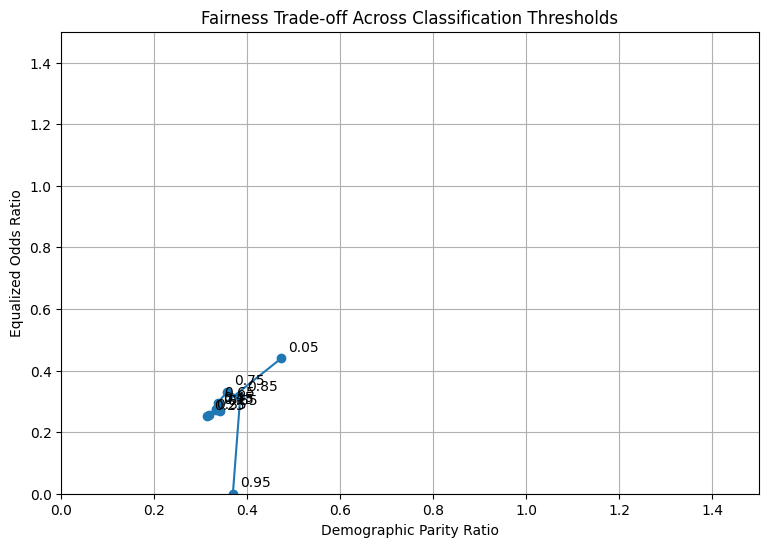

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.plot(
    fairness_results["DP Ratio"],
    fairness_results["EO Ratio"],
    marker="o"
)

for _, row in fairness_results.iterrows():
    plt.annotate(
        str(row["Threshold"]),
        (row["DP Ratio"], row["EO Ratio"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)
plt.xlabel("Demographic Parity Ratio")
plt.ylabel("Equalized Odds Ratio")
plt.title("Fairness Trade-off Across Classification Thresholds")
plt.grid(True)
plt.show()

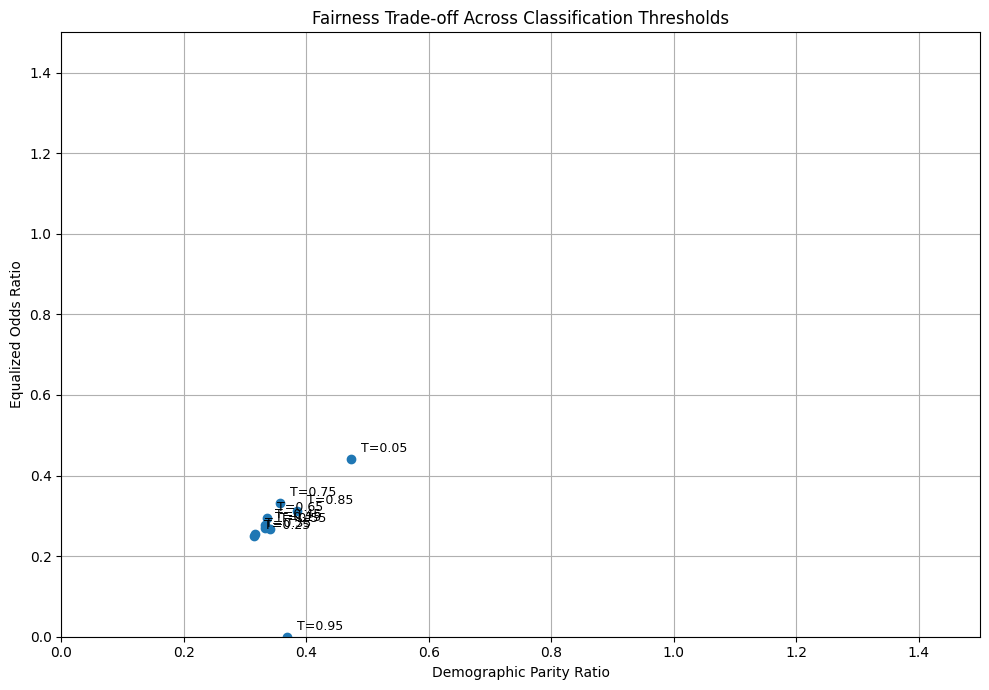

In [22]:
plt.figure(figsize=(10, 7))

plt.scatter(
    fairness_results["DP Ratio"],
    fairness_results["EO Ratio"]
)

for _, row in fairness_results.iterrows():
    plt.annotate(
        f'T={row["Threshold"]:.2f}',
        (row["DP Ratio"], row["EO Ratio"]),
        xytext=(7, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)
plt.xlabel("Demographic Parity Ratio")
plt.ylabel("Equalized Odds Ratio")
plt.title("Fairness Trade-off Across Classification Thresholds")
plt.grid(True)
plt.tight_layout()
plt.show()

In [23]:
import statsmodels.api as sm
import pandas as pd
import numpy as np

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

corrected_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

corrected_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore"))
])

corrected_preprocessor = ColumnTransformer([
    ("numeric", corrected_numeric_pipeline, numeric_features),
    ("categorical", corrected_categorical_pipeline, categorical_features)
])

X_full_train_array = corrected_preprocessor.fit_transform(X_train)
X_full_train_array = (
    X_full_train_array.toarray()
    if hasattr(X_full_train_array, "toarray")
    else X_full_train_array
)

feature_names = corrected_preprocessor.get_feature_names_out()

X_full_train = pd.DataFrame(
    X_full_train_array,
    columns=feature_names,
    index=X_train.index
)

def fit_full_logistic(X_data, y_data):
    X_data = X_data.loc[:, X_data.nunique() > 1].copy()
    X_data = sm.add_constant(X_data, has_constant="add")
    model = sm.GLM(
        y_data,
        X_data,
        family=sm.families.Binomial()
    ).fit(maxiter=200)

    ci = model.conf_int()

    results = pd.DataFrame({
        "Coefficient": model.params,
        "CI Lower": ci[0],
        "CI Upper": ci[1],
        "P-value": model.pvalues
    })

    return model, results

full_feature_model, full_feature_results = fit_full_logistic(
    X_full_train,
    y_train
)

print("Full-feature model fitted.")
print("Training observations:", len(y_train))
print("Encoded features:", X_full_train.shape[1])
print("Converged:", full_feature_model.converged)

display(
    full_feature_results.sort_values("P-value").head(20)
)

/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/families/links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)


Full-feature model fitted.
Training observations: 22792
Encoded features: 97
Converged: False


/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


,Coefficient,CI Lower,CI Upper,P-value
const,-6.370289e+14,-6.370289e+14,-6.370289e+14,0.0
numeric__age,1.302500e+14,1.302500e+14,1.302500e+14,0.0
numeric__fnlwgt,4.159457e+13,4.159457e+13,4.159457e+13,0.0
numeric__education_num,3.527755e+14,3.527755e+14,3.527755e+14,0.0
numeric__capital_gain,8.842181e+14,8.842181e+14,8.842181e+14,0.0
numeric__capital_loss,1.606089e+14,1.606089e+14,1.606089e+14,0.0
numeric__hours_per_week,1.540998e+14,1.540998e+14,1.540998e+14,0.0
categorical__workclass_Local-gov,-1.485145e+14,-1.485145e+14,-1.485145e+14,0.0
categorical__workclass_Never-worked,-2.858710e+15,-2.858710e+15,-2.858710e+15,0.0
categorical__workclass_Private,-1.359103e+14,-1.359103e+14,-1.359103e+14,0.0


In [24]:
print("Full model converged:", full_feature_model.converged)

for group in ["Female", "Male"]:
    group_mask = X_train["sex"].eq(group)

    group_model, group_results = fit_full_logistic(
        X_full_train.loc[group_mask],
        y_train.loc[group_mask]
    )

    print("\nGroup:", group)
    print("Observations:", int(group_mask.sum()))
    print("Converged:", group_model.converged)

    display(
        group_results.sort_values("P-value").head(15)
    )

Full model converged: False


/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/families/links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)



Group: Female
Observations: 7464
Converged: False


/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


,Coefficient,CI Lower,CI Upper,P-value
const,-5.472531e+15,-5.472531e+15,-5.472531e+15,0.0
numeric__age,1.410121e+14,1.410120e+14,1.410121e+14,0.0
numeric__fnlwgt,-2.462750e+13,-2.462751e+13,-2.462750e+13,0.0
numeric__education_num,5.578625e+14,5.578625e+14,5.578625e+14,0.0
numeric__capital_gain,5.427171e+14,5.427171e+14,5.427171e+14,0.0
numeric__capital_loss,1.201626e+14,1.201626e+14,1.201626e+14,0.0
numeric__hours_per_week,9.998023e+13,9.998023e+13,9.998023e+13,0.0
categorical__workclass_Local-gov,1.252094e+14,1.252094e+14,1.252094e+14,0.0
categorical__workclass_Never-worked,-4.080234e+15,-4.080234e+15,-4.080233e+15,0.0
categorical__workclass_Private,9.518458e+13,9.518457e+13,9.518459e+13,0.0


/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/families/links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)



Group: Male
Observations: 15328
Converged: False


/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


,Coefficient,CI Lower,CI Upper,P-value
const,-6.659912e+14,-6.659912e+14,-6.659911e+14,0.0
numeric__age,1.512498e+14,1.512498e+14,1.512498e+14,0.0
numeric__fnlwgt,6.011305e+13,6.011305e+13,6.011306e+13,0.0
numeric__education_num,4.203845e+14,4.203845e+14,4.203845e+14,0.0
numeric__capital_gain,9.428101e+14,9.428101e+14,9.428101e+14,0.0
numeric__capital_loss,2.222104e+14,2.222104e+14,2.222104e+14,0.0
numeric__hours_per_week,1.966196e+14,1.966196e+14,1.966196e+14,0.0
categorical__workclass_Local-gov,-4.779246e+14,-4.779246e+14,-4.779246e+14,0.0
categorical__workclass_Never-worked,-2.418110e+15,-2.418110e+15,-2.418110e+15,0.0
categorical__workclass_Private,-4.728405e+14,-4.728405e+14,-4.728405e+14,0.0


In [25]:
print("Full model converged:", full_feature_model.converged)

print("Maximum absolute coefficient:")
print(full_feature_model.params.abs().max())

print("Largest standard errors:")
print(full_feature_model.bse.abs().sort_values(ascending=False).head(10))

print("Any infinite coefficients:")
print(np.isinf(full_feature_model.params).any())

print("Any infinite standard errors:")
print(np.isinf(full_feature_model.bse).any())

Full model converged: False
Maximum absolute coefficient:
4745736754612465.0
Largest standard errors:
categorical__native_country_Holand-Netherlands            6.927846e+07
categorical__native_country_Scotland                      3.750314e+07
categorical__native_country_Honduras                      2.796811e+07
categorical__workclass_Never-worked                       2.758093e+07
categorical__native_country_Hungary                       2.704273e+07
categorical__native_country_Yugoslavia                    2.703608e+07
categorical__native_country_Trinadad&Tobago               2.629980e+07
categorical__native_country_Outlying-US(Guam-USVI-etc)    2.560950e+07
categorical__occupation_Armed-Forces                      2.555713e+07
categorical__native_country_Thailand                      2.535524e+07
dtype: float64
Any infinite coefficients:
False
Any infinite standard errors:
False


In [26]:
X_stable = X_train.drop(
    columns=["native_country", "fnlwgt"]
).copy()

X_stable["occupation"] = X_stable["occupation"].fillna("Unknown")
X_stable["workclass"] = X_stable["workclass"].fillna("Unknown")

stable_numeric = X_stable.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

stable_categorical = X_stable.select_dtypes(
    include=["object"]
).columns.tolist()

stable_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), stable_numeric),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
            min_frequency=100
        ))
    ]), stable_categorical)
])

stable_array = stable_preprocessor.fit_transform(X_stable)
stable_array = (
    stable_array.toarray()
    if hasattr(stable_array, "toarray")
    else stable_array
)

X_stable_train = pd.DataFrame(
    stable_array,
    columns=stable_preprocessor.get_feature_names_out(),
    index=X_train.index
)

stable_model, stable_results = fit_full_logistic(
    X_stable_train,
    y_train
)

print("Converged:", stable_model.converged)
print("Maximum absolute coefficient:", stable_model.params.abs().max())

display(stable_results.sort_values("P-value").head(15))

/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/families/links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)


Converged: False
Maximum absolute coefficient: 4519634754948040.0


/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


,Coefficient,CI Lower,CI Upper,P-value
const,-7.526114e+14,-7.526114e+14,-7.526113e+14,0.0
numeric__age,1.566195e+14,1.566195e+14,1.566195e+14,0.0
numeric__education_num,3.058018e+14,3.058018e+14,3.058018e+14,0.0
numeric__capital_gain,7.591312e+14,7.591312e+14,7.591312e+14,0.0
numeric__capital_loss,-5.660475e+11,-5.660484e+11,-5.660466e+11,0.0
numeric__hours_per_week,1.716844e+14,1.716844e+14,1.716844e+14,0.0
categorical__workclass_Local-gov,-4.250398e+14,-4.250398e+14,-4.250397e+14,0.0
categorical__workclass_Private,-3.463360e+14,-3.463360e+14,-3.463360e+14,0.0
categorical__workclass_Self-emp-inc,-1.534417e+14,-1.534417e+14,-1.534417e+14,0.0
categorical__workclass_Self-emp-not-inc,-5.509018e+14,-5.509018e+14,-5.509017e+14,0.0


In [27]:
print("X_train exists:", "X_train" in globals())
print("df exists:", "df" in globals())
print("fit_full_logistic exists:", "fit_full_logistic" in globals())
print("Pipeline exists:", "Pipeline" in globals())
print("ColumnTransformer exists:", "ColumnTransformer" in globals())

X_train exists: True
df exists: True
fit_full_logistic exists: True
Pipeline exists: True
ColumnTransformer exists: True


In [28]:
print("Dataset:", df.shape)
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Preprocessor ready:", "preprocessor" in globals())
print("Logistic model ready:", "logistic_model" in globals())

Dataset: (32561, 16)
Training set: (22792, 14)
Test set: (9769, 14)
Preprocessor ready: True
Logistic model ready: True


In [29]:
X_stable = X_train.drop(
    columns=["native_country", "fnlwgt"]
).copy()

stable_numeric = X_stable.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

stable_categorical = X_stable.select_dtypes(
    include=["object"]
).columns.tolist()

stable_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), stable_numeric),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
            min_frequency=100
        ))
    ]), stable_categorical)
])

stable_array = stable_preprocessor.fit_transform(X_stable)

stable_array = (
    stable_array.toarray()
    if hasattr(stable_array, "toarray")
    else stable_array
)

X_stable_train = pd.DataFrame(
    stable_array,
    columns=stable_preprocessor.get_feature_names_out(),
    index=X_train.index
)

print("Stable training matrix:", X_stable_train.shape)

Stable training matrix: (22792, 55)


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

stable_model = LogisticRegression(
    max_iter=3000,
    C=1.0,
    random_state=736
)

stable_model.fit(X_stable_train, y_train)

X_stable_test_raw = X_test.drop(
    columns=["native_country", "fnlwgt"]
).copy()

stable_test_array = stable_preprocessor.transform(X_stable_test_raw)

stable_test_array = (
    stable_test_array.toarray()
    if hasattr(stable_test_array, "toarray")
    else stable_test_array
)

X_stable_test = pd.DataFrame(
    stable_test_array,
    columns=stable_preprocessor.get_feature_names_out(),
    index=X_test.index
)

stable_predictions = stable_model.predict(X_stable_test)

print("Training features:", X_stable_train.shape[1])
print("Test features:", X_stable_test.shape[1])
print("Accuracy:", round(accuracy_score(y_test, stable_predictions) * 100, 2), "%")
print(classification_report(y_test, stable_predictions))

Training features: 55
Test features: 55
Accuracy: 85.22 %
              precision    recall  f1-score   support

           0       0.88      0.94      0.91      7417
           1       0.74      0.59      0.66      2352

    accuracy                           0.85      9769
   macro avg       0.81      0.76      0.78      9769
weighted avg       0.85      0.85      0.85      9769



In [31]:
import statsmodels.api as sm
import pandas as pd

simpson_features = [
    "age",
    "education_num",
    "hours_per_week",
    "capital_gain"
]

simpson_data = X_train[simpson_features + ["sex"]].copy()
simpson_data["income_binary"] = y_train

def fit_group_model(data, group_name):
    subset = data if group_name == "Full" else data[data["sex"] == group_name]
    X_group = sm.add_constant(subset[simpson_features].astype(float))
    y_group = subset["income_binary"].astype(int)
    model = sm.Logit(y_group, X_group).fit(disp=False, maxiter=200)
    return pd.DataFrame({
        "Coefficient": model.params,
        "P-value": model.pvalues,
        "CI Lower": model.conf_int()[0],
        "CI Upper": model.conf_int()[1]
    })

simpson_results = {
    "Full": fit_group_model(simpson_data, "Full"),
    "Female": fit_group_model(simpson_data, "Female"),
    "Male": fit_group_model(simpson_data, "Male")
}

for group, result in simpson_results.items():
    print("\n", group)
    display(result.round(5))


 Full


,Coefficient,P-value,CI Lower,CI Upper
const,-8.36822,0.0,-8.63626,-8.10018
age,0.04399,0.0,0.04115,0.04683
education_num,0.33339,0.0,0.31757,0.34921
hours_per_week,0.04049,0.0,0.03744,0.04355
capital_gain,0.00030,0.0,0.00028,0.00032



 Female


,Coefficient,P-value,CI Lower,CI Upper
const,-8.03256,0.0,-8.59374,-7.47137
age,0.02941,0.0,0.02335,0.03546
education_num,0.36123,0.0,0.32279,0.39967
hours_per_week,0.01799,0.0,0.01105,0.02493
capital_gain,0.00032,0.0,0.00028,0.00037



 Male


,Coefficient,P-value,CI Lower,CI Upper
const,-8.18106,0.0,-8.49402,-7.86810
age,0.04691,0.0,0.04358,0.05025
education_num,0.34141,0.0,0.32355,0.35927
hours_per_week,0.03794,0.0,0.03441,0.04148
capital_gain,0.00028,0.0,0.00026,0.00031


In [32]:
import statsmodels.formula.api as smf

interaction_data = X_train[
    ["age", "education_num", "hours_per_week", "capital_gain", "sex"]
].copy()

interaction_data["income_binary"] = y_train
interaction_data["female"] = (
    interaction_data["sex"].str.strip() == "Female"
).astype(int)

interaction_model = smf.logit(
    "income_binary ~ age + education_num + hours_per_week + capital_gain + female + age:female + education_num:female + hours_per_week:female + capital_gain:female",
    data=interaction_data
).fit(disp=False, maxiter=200)

interaction_results = pd.DataFrame({
    "Coefficient": interaction_model.params,
    "P-value": interaction_model.pvalues,
    "CI Lower": interaction_model.conf_int()[0],
    "CI Upper": interaction_model.conf_int()[1]
})

display(interaction_results.round(6))

,Coefficient,P-value,CI Lower,CI Upper
Intercept,-8.181061,0.000000,-8.494023,-7.868099
age,0.046912,0.000000,0.043575,0.050249
education_num,0.341411,0.000000,0.323549,0.359273
hours_per_week,0.037942,0.000000,0.034407,0.041478
capital_gain,0.000284,0.000000,0.000258,0.000309
female,0.148504,0.650564,-0.494048,0.791055
age:female,-0.017507,0.000001,-0.024421,-0.010593
education_num:female,0.019819,0.359501,-0.022573,0.062210
hours_per_week:female,-0.019955,0.000001,-0.027745,-0.012164
capital_gain:female,0.000039,0.139668,-0.000013,0.000090


In [33]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

full_ovb_model = LogisticRegression(
    max_iter=3000,
    C=1.0,
    random_state=736
)

full_ovb_model.fit(X_stable_train, y_train)

X_reduced_train = X_stable_train.drop(
    columns=[c for c in X_stable_train.columns if "age" in c.lower()]
)

reduced_ovb_model = LogisticRegression(
    max_iter=3000,
    C=1.0,
    random_state=736
)

reduced_ovb_model.fit(X_reduced_train, y_train)

full_coefficients = pd.Series(
    full_ovb_model.coef_[0],
    index=X_stable_train.columns
)

reduced_coefficients = pd.Series(
    reduced_ovb_model.coef_[0],
    index=X_reduced_train.columns
)

shared_features = [
    feature for feature in reduced_coefficients.index
    if feature in full_coefficients.index
]

ovb_results = pd.DataFrame({
    "Full coefficient": full_coefficients[shared_features],
    "Reduced coefficient": reduced_coefficients[shared_features]
})

ovb_results["Absolute change"] = (
    ovb_results["Reduced coefficient"] -
    ovb_results["Full coefficient"]
)

ovb_results["Percentage change"] = np.where(
    ovb_results["Full coefficient"].abs() > 1e-10,
    ovb_results["Absolute change"] /
    ovb_results["Full coefficient"].abs() * 100,
    np.nan
)

display(
    ovb_results.reindex(
        ovb_results["Absolute change"].abs()
        .sort_values(ascending=False).index
    ).head(10).round(4)
)

,Full coefficient,Reduced coefficient,Absolute change,Percentage change
categorical__occupation_Handlers-cleaners,-0.6891,-1.3076,-0.6185,-89.7657
categorical__occupation_Craft-repair,0.1497,-0.4478,-0.5975,-399.0913
categorical__occupation_Machine-op-inspct,-0.0801,-0.6774,-0.5973,-745.7876
categorical__occupation_Farming-fishing,-0.9259,-1.4974,-0.5715,-61.7258
categorical__occupation_Transport-moving,-0.0643,-0.6236,-0.5593,-869.8174
categorical__occupation_Sales,0.2599,-0.2992,-0.5591,-215.0990
categorical__occupation_Tech-support,0.6723,0.1238,-0.5485,-81.5818
categorical__occupation_Protective-serv,0.5033,-0.0438,-0.5471,-108.6947
categorical__occupation_Other-service,-0.7532,-1.2953,-0.5421,-71.9671
categorical__occupation_Prof-specialty,0.2072,-0.3060,-0.5132,-247.6760


In [34]:
core_features = [
    "numeric__education_num",
    "numeric__hours_per_week",
    "numeric__capital_gain",
    "numeric__capital_loss"
]

available_features = [
    feature for feature in core_features
    if feature in full_coefficients.index
    and feature in reduced_coefficients.index
]

core_ovb_results = pd.DataFrame({
    "Full coefficient": full_coefficients[available_features],
    "Reduced coefficient": reduced_coefficients[available_features]
})

core_ovb_results["Absolute change"] = (
    core_ovb_results["Reduced coefficient"]
    - core_ovb_results["Full coefficient"]
)

core_ovb_results["Percentage change"] = (
    core_ovb_results["Absolute change"]
    / core_ovb_results["Full coefficient"].abs()
    * 100
)

display(core_ovb_results.round(4))

,Full coefficient,Reduced coefficient,Absolute change,Percentage change
numeric__education_num,0.8707,0.8353,-0.0354,-4.0649
numeric__hours_per_week,0.3854,0.3536,-0.0318,-8.2530
numeric__capital_gain,2.2279,2.2612,0.0333,1.4932
numeric__capital_loss,0.2631,0.2660,0.0028,1.0776


In [35]:
stable_probabilities = stable_model.predict_proba(X_stable_test)[:, 1]

high_confidence_mask = (
    ((stable_probabilities >= 0.75) & (y_test.to_numpy() == 0)) |
    ((stable_probabilities <= 0.25) & (y_test.to_numpy() == 1))
)

high_confidence_errors = X_test.loc[high_confidence_mask].copy()
high_confidence_errors["actual_income"] = y_test.loc[high_confidence_errors.index]
high_confidence_errors["predicted_probability"] = stable_probabilities[
    X_test.index.get_indexer(high_confidence_errors.index)
]

print("High-confidence errors:", len(high_confidence_errors))
print("Percentage of test set:", round(len(high_confidence_errors) / len(y_test) * 100, 2), "%")

sample_errors = high_confidence_errors.sample(
    n=min(50, len(high_confidence_errors)),
    random_state=736
)

print("\nGender distribution: sample vs full test set")
display(pd.DataFrame({
    "Error sample (%)": sample_errors["sex"].value_counts(normalize=True) * 100,
    "Full test set (%)": X_test["sex"].value_counts(normalize=True) * 100
}).fillna(0).round(2))

print("\nRace distribution: sample vs full test set")
display(pd.DataFrame({
    "Error sample (%)": sample_errors["race"].value_counts(normalize=True) * 100,
    "Full test set (%)": X_test["race"].value_counts(normalize=True) * 100
}).fillna(0).round(2))

High-confidence errors: 453
Percentage of test set: 4.64 %

Gender distribution: sample vs full test set


,Error sample (%),Full test set (%)
sex,,
Male,72.0,66.15
Female,28.0,33.85



Race distribution: sample vs full test set


,Error sample (%),Full test set (%)
race,,
Amer-Indian-Eskimo,0.0,1.10
Asian-Pac-Islander,4.0,3.20
Black,4.0,9.77
Other,0.0,0.95
White,92.0,84.98


In [36]:
import numpy as np
import pandas as pd

thresholds = np.round(np.arange(0.05, 1.00, 0.10), 2)

actual = y_test.to_numpy()
sex_test = X_test["sex"].str.strip().to_numpy()
probabilities = stable_model.predict_proba(X_stable_test)[:, 1]

fairness_rows = []

for threshold in thresholds:
    predicted = (probabilities >= threshold).astype(int)

    group_metrics = {}

    for group in ["Female", "Male"]:
        mask = sex_test == group
        y_true = actual[mask]
        y_pred = predicted[mask]

        tp = np.sum((y_true == 1) & (y_pred == 1))
        fp = np.sum((y_true == 0) & (y_pred == 1))
        tn = np.sum((y_true == 0) & (y_pred == 0))
        fn = np.sum((y_true == 1) & (y_pred == 0))

        group_metrics[group] = {
            "selection_rate": np.mean(y_pred),
            "tpr": tp / (tp + fn) if tp + fn else np.nan,
            "fpr": fp / (fp + tn) if fp + tn else np.nan,
            "precision": tp / (tp + fp) if tp + fp else np.nan
        }

    female = group_metrics["Female"]
    male = group_metrics["Male"]

    dp = female["selection_rate"] / male["selection_rate"] if male["selection_rate"] else np.nan
    tpr_ratio = female["tpr"] / male["tpr"] if male["tpr"] else np.nan
    fpr_ratio = female["fpr"] / male["fpr"] if male["fpr"] else np.nan
    eo = min(tpr_ratio, fpr_ratio) if not np.isnan(tpr_ratio) and not np.isnan(fpr_ratio) else np.nan
    pp = female["precision"] / male["precision"] if male["precision"] else np.nan

    fairness_rows.append({
        "Threshold": threshold,
        "DP (Female/Male)": dp,
        "TPR ratio (Female/Male)": tpr_ratio,
        "FPR ratio (Female/Male)": fpr_ratio,
        "EO (min TPR/FPR ratio)": eo,
        "PP (Female/Male)": pp
    })

fairness_table = pd.DataFrame(fairness_rows)
display(fairness_table.round(3))

,Threshold,DP (Female/Male),TPR ratio (Female/Male),FPR ratio (Female/Male),EO (min TPR/FPR ratio),PP (Female/Male)
0,0.05,0.474,0.970,0.440,0.440,0.725
1,0.15,0.333,0.896,0.272,0.272,0.952
2,0.25,0.310,0.859,0.246,0.246,0.983
3,0.35,0.311,0.868,0.246,0.246,0.991
4,0.45,0.327,0.904,0.266,0.266,0.981
5,0.55,0.324,0.921,0.247,0.247,1.006
6,0.65,0.334,0.924,0.285,0.285,0.980
7,0.75,0.357,0.989,0.318,0.318,0.981
8,0.85,0.386,1.106,0.253,0.253,1.014
9,0.95,0.369,1.059,0.000,0.000,1.018


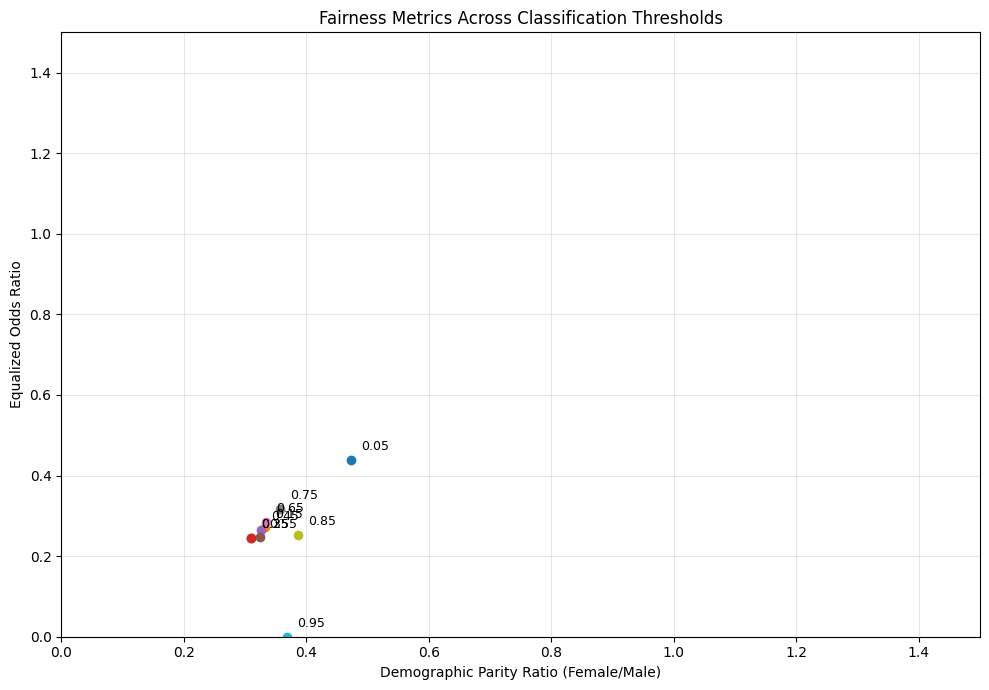

In [38]:
plt.figure(figsize=(10, 7))

for _, row in fairness_table.iterrows():
    x = row["DP (Female/Male)"]
    y = row["EO (min TPR/FPR ratio)"]
    threshold = row["Threshold"]

    plt.scatter(x, y)
    plt.annotate(
        f'{threshold:.2f}',
        (x, y),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=9
    )

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)
plt.xlabel("Demographic Parity Ratio (Female/Male)")
plt.ylabel("Equalized Odds Ratio")
plt.title("Fairness Metrics Across Classification Thresholds")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()